## Exploratory data analysis

Dans ce notebook on va analyser les datasets présent dans `../data/`

## Importation des bibliothèques nécessaires

- Pandas
- Numpy
- Matplotlib
- Seaborn
- LabelEncoder

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

In [2]:
app_train = pd.read_csv('../data/application_train.csv')
print('Training data shape: ', app_train.shape)
app_train.head()


Training data shape:  (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
app_train['SK_ID_CURR'].nunique()

307511

L'ensemble de données d'entrainement comporte 307 511 observations (chacune correspondant à un prêt distinct) et 122 caractéristiques (variables), dont la variable TARGET (la classe que nous souhaitons prédire).

In [4]:
app_test = pd.read_csv('../data/application_test.csv')
print('Testing data shape: ', app_test.shape)
app_test.head()

Testing data shape:  (48744, 121)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
app_test['SK_ID_CURR'].nunique()

48744

L'ensemble de test est nettement plus petit et ne comporte pas de colonne « TARGET ».

In [6]:
app_train['TARGET'].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

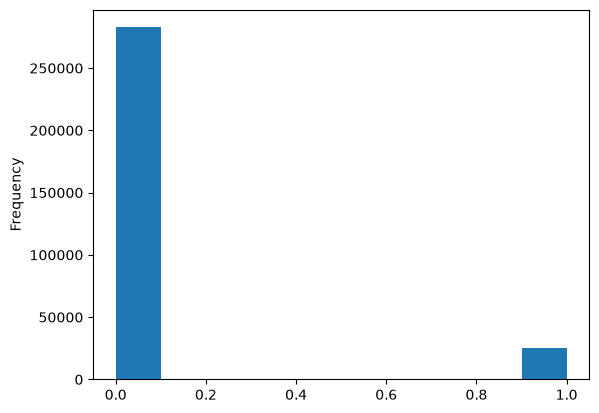

In [7]:
app_train['TARGET'].astype(int).plot.hist();

282686/307511 = 91,93% => 92% des emprunteurs remboursent leur prêt

24825/307511 = 8,07% => 8% des emprunteurs ne remboursent pas leur prêt

Un déséquilibre dans notre colonne `TARGET`

Le nombre de prêts remboursés dans les délais est bien supérieur à celui des prêts non remboursés. Lorsque l'on passe à des modèles d'apprentissage automatique plus sophistiqués, il est possible de pondérer les classes en fonction de leur représentation dans les données afin de tenir compte de ce déséquilibre.

In [8]:
# Function to calculate missing values by column# Funct 
def missing_values_table(df):
        # Total missing values
        mis_val = df.isnull().sum()
        
        # Percentage of missing values
        mis_val_percent = 100 * df.isnull().sum() / len(df)
        
        # Make a table with the results
        mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)
        
        # Rename the columns
        mis_val_table_ren_columns = mis_val_table.rename(
        columns = {0 : 'Missing Values', 1 : '% of Total Values'})
        
        # Sort the table by percentage of missing descending
        mis_val_table_ren_columns = mis_val_table_ren_columns[
            mis_val_table_ren_columns.iloc[:,1] != 0].sort_values(
        '% of Total Values', ascending=False).round(1)
        
        # Print some summary information
        print ("Your selected dataframe has " + str(df.shape[1]) + " columns.\n"      
            "There are " + str(mis_val_table_ren_columns.shape[0]) +
              " columns that have missing values.")
        
        # Return the dataframe with missing information
        return mis_val_table_ren_columns

In [9]:
# Missing values statistics
missing_values = missing_values_table(app_train)
missing_values.head(20)

Your selected dataframe has 122 columns.
There are 67 columns that have missing values.


,Missing Values,% of Total Values
COMMONAREA_MEDI,214865,69.9
COMMONAREA_MODE,214865,69.9
COMMONAREA_AVG,214865,69.9
NONLIVINGAPARTMENTS_MODE,213514,69.4
NONLIVINGAPARTMENTS_MEDI,213514,69.4
NONLIVINGAPARTMENTS_AVG,213514,69.4
FONDKAPREMONT_MODE,210295,68.4
LIVINGAPARTMENTS_AVG,210199,68.4
LIVINGAPARTMENTS_MEDI,210199,68.4
LIVINGAPARTMENTS_MODE,210199,68.4


Au moment de construire nos modèles d’apprentissage automatique, nous devrons compléter ces valeurs manquantes (ce que l’on appelle l’imputation). Dans des travaux ultérieurs, nous utiliserons des modèles tels que XGBoost, capables de gérer les valeurs manquantes sans avoir recours à l’imputation. Une autre option consisterait à supprimer les colonnes présentant un pourcentage élevé de valeurs manquantes, bien qu’il soit impossible de savoir à l’avance si ces colonnes seront utiles à notre modèle. C’est pourquoi nous conserverons toutes les colonnes pour l’instant.

In [10]:
# Number of each type of column
app_train.dtypes.value_counts()

float64    65
int64      41
str        16
Name: count, dtype: int64

In [11]:
# Number of unique classes in each object column
app_train.select_dtypes('object').apply(pd.Series.nunique, axis = 0)

/tmp/ipykernel_26005/728169046.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  app_train.select_dtypes('object').apply(pd.Series.nunique, axis = 0)


NAME_CONTRACT_TYPE             2
CODE_GENDER                    3
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
NAME_TYPE_SUITE                7
NAME_INCOME_TYPE               8
NAME_EDUCATION_TYPE            5
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
OCCUPATION_TYPE               18
WEEKDAY_APPR_PROCESS_START     7
ORGANIZATION_TYPE             58
FONDKAPREMONT_MODE             4
HOUSETYPE_MODE                 3
WALLSMATERIAL_MODE             7
EMERGENCYSTATE_MODE            2
dtype: int64

La plupart des variables catégorielles comportent un nombre relativement faible de valeurs distinctes. Il va falloir trouver un moyen de traiter ces variables catégorielles !

Avant d'aller plus loin, il est nécessaire d'encoder ces variables catégorielles, car la plupart des modèles de machine learning ne peuvent pas les traiter directement (à l'exception de certains modèles comme LightGBM ou CatBoost).

Il existe deux manières principales d'effectuer ce processus :

- **Label encoding :** attribuer un nombre entier à chaque catégorie unique d'une variable catégorielle. Aucune nouvelle colonne n'est créée.

- **One-hot encoding :** créer une nouvelle colonne pour chaque catégorie unique d'une variable catégorielle. Chaque observation reçoit un 1 dans la colonne correspondant à sa catégorie et un 0 dans toutes les autres nouvelles colonnes.

Le problème du **label encoding** est que le modèle peut interpréter les entiers comme un ordre entre les catégories, ce qui introduit une relation artificielle qui n'existe pas dans les données. Le **label encoding** convient lorsque la variable catégorielle ne contient que deux valeurs (Homme / Femme), car aucune hiérarchie parasite ne peut apparaître. Au-delà de 2 catégories uniques, le **one-hot encoding** est l'option la plus sûre.

J'utiliserai donc le **label encoding** pour les variables catégorielles à 2 catégories uniques, et le **one-hot encoding** pour celles qui en comptent davantage.


In [12]:
# Create a label encoder object
le = LabelEncoder()
le_count = 0

# Iterate through the columns
for col in app_train:
    if app_train[col].dtype in ['object', 'str', 'string']:
        # If 2 or fewer unique categories
        if len(list(app_train[col].unique())) <= 2:
            # Train on the training data
            le.fit(app_train[col])
            # Transform both training and testing data
            app_train[col] = le.transform(app_train[col])
            app_test[col] = le.transform(app_test[col])
            
            # Keep track of how many columns were label encoded
            le_count += 1
            
print('%d columns were label encoded.' % le_count)

3 columns were label encoded.


In [13]:
# one-hot encoding of categorical variables
app_train = pd.get_dummies(app_train)
app_test = pd.get_dummies(app_test)

print('Training Features shape: ', app_train.shape)
print('Testing Features shape: ', app_test.shape)

Training Features shape:  (307511, 243)
Testing Features shape:  (48744, 239)


#### Alignement des données d'entraînement et de test

Les données d'entraînement et de test doivent comporter les mêmes caractéristiques (colonnes). Le codage « one-hot » a généré davantage de colonnes dans les données d'entraînement, car certaines variables catégorielles comportaient des catégories non représentées dans les données de test.

Pour supprimer les colonnes des données d'entraînement qui ne figurent pas dans les données de test, nous devons aligner les dataframes. Nous commençons par extraire la colonne « target » des données d'entraînement (car elle n'apparaît pas dans les données de test, mais nous devons conserver cette information).

Lors de l'alignement, nous devons veiller à définir `axis = 1` afin d'aligner les dataframes en fonction des colonnes et non des lignes !

In [14]:
train_labels = app_train['TARGET']

# Align the training and testing data, keep only columns present in both dataframes
app_train, app_test = app_train.align(app_test, join = 'inner', axis = 1)

# Add the target back in
app_train['TARGET'] = train_labels

print('Training Features shape: ', app_train.shape)
print('Testing Features shape: ', app_test.shape)

Training Features shape:  (307511, 240)
Testing Features shape:  (48744, 239)


Les ensembles de données d'entraînement et de test présentent désormais les mêmes caractéristiques

Cependant, le nombre de caractéristiques a considérablement augmenté en raison du codage « one-hot ». À un moment donné, nous souhaiterons probablement recourir à la **réduction de dimensionnalité** (en supprimant les caractéristiques non pertinentes) afin de réduire la taille des ensembles de données.

In [15]:
app_train.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 240 columns):
 #    Column                                             Dtype  
---   ------                                             -----  
 0    SK_ID_CURR                                         int64  
 1    NAME_CONTRACT_TYPE                                 int64  
 2    FLAG_OWN_CAR                                       int64  
 3    FLAG_OWN_REALTY                                    int64  
 4    CNT_CHILDREN                                       int64  
 5    AMT_INCOME_TOTAL                                   float64
 6    AMT_CREDIT                                         float64
 7    AMT_ANNUITY                                        float64
 8    AMT_GOODS_PRICE                                    float64
 9    REGION_POPULATION_RELATIVE                         float64
 10   DAYS_BIRTH                                         int64  
 11   DAYS_EMPLOYED                                   

In [16]:
app_test.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 48744 entries, 0 to 48743
Data columns (total 239 columns):
 #    Column                                             Dtype  
---   ------                                             -----  
 0    SK_ID_CURR                                         int64  
 1    NAME_CONTRACT_TYPE                                 int64  
 2    FLAG_OWN_CAR                                       int64  
 3    FLAG_OWN_REALTY                                    int64  
 4    CNT_CHILDREN                                       int64  
 5    AMT_INCOME_TOTAL                                   float64
 6    AMT_CREDIT                                         float64
 7    AMT_ANNUITY                                        float64
 8    AMT_GOODS_PRICE                                    float64
 9    REGION_POPULATION_RELATIVE                         float64
 10   DAYS_BIRTH                                         int64  
 11   DAYS_EMPLOYED                                     

#### Retour à l'analyse exploratoire des données

In [17]:
(app_train['DAYS_BIRTH'] / -365).describe()

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: DAYS_BIRTH, dtype: float64

Ces âges semblent raisonnables. Il n'y a pas d'aberrations, ni à l'extrémité supérieure ni à l'extrémité inférieure de la fourchette.

In [18]:
app_train['DAYS_EMPLOYED'].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

Cela me paraît étrange ! La valeur maximale (qui est positive) est d'environ 1000 ans !

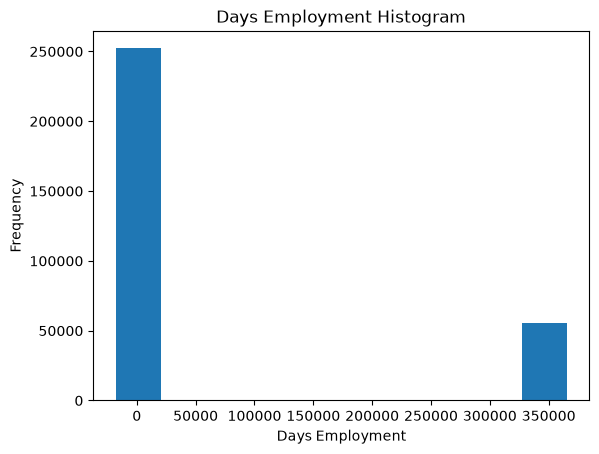

In [19]:
app_train['DAYS_EMPLOYED'].plot.hist(title = 'Days Employment Histogram');
plt.xlabel('Days Employment');

Par simple curiosité, isolons les clients présentant des anomalies et voyons s'ils ont tendance à avoir des taux de défaut de paiement plus élevés ou plus faibles que le reste des clients.

In [20]:
anom = app_train[app_train['DAYS_EMPLOYED'] == 365243]
non_anom = app_train[app_train['DAYS_EMPLOYED'] != 365243]
print('The non-anomalies default on %0.2f%% of loans' % (100 * non_anom['TARGET'].mean()))
print('The anomalies default on %0.2f%% of loans' % (100 * anom['TARGET'].mean()))
print('There are %d anomalous days of employment' % len(anom))

The non-anomalies default on 8.66% of loans
The anomalies default on 5.40% of loans
There are 55374 anomalous days of employment


L'analyse a montré que les observations anomalies présentent un taux de défaut plus faible que le reste : ces valeurs portent donc une information, il ne faut ni les supprimer ni les traiter comme des erreurs.

Stratégie retenue :

1. Remplacer les valeurs anomalies par np.nan (imputation ultérieure avant l'entraînement).
2. Créer une colonne booléenne supplémentaire indiquant si la valeur d'origine était anomalies, afin de préserver ce signal pour le modèle.

Justification : toutes les anomalies partagent exactement la même valeur, ce qui suggère un comportement commun (probablement une convention de saisie) ; conserver cette information explicite est plus sûr que de la perdre dans l'imputation.

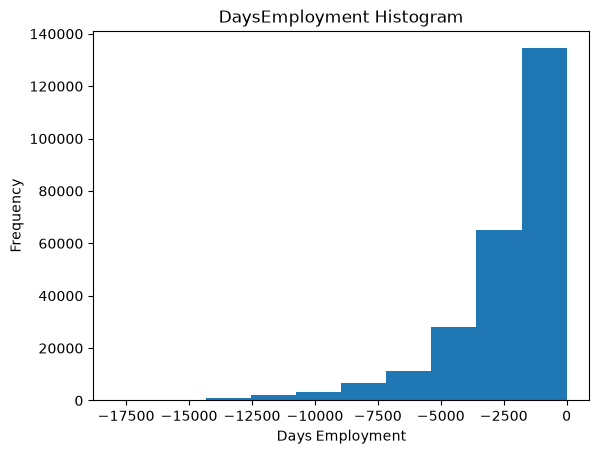

In [21]:
# 1. Créer une colonne booléenne pour conserver l'information de l'anomalie
app_train['DAYS_EMPLOYED_ANOM'] = app_train['DAYS_EMPLOYED'] == 365243
  
# 2. Remplacer la valeur aberrante par NaN        
app_train['DAYS_EMPLOYED'] = app_train['DAYS_EMPLOYED'].replace({365243:     
    np.nan})
  
# Même transformation au jeu de test
app_test['DAYS_EMPLOYED_ANOM'] = app_test['DAYS_EMPLOYED'] == 365243
app_test['DAYS_EMPLOYED'] = app_test['DAYS_EMPLOYED'].replace({365243:np.nan})

# 3. Tracer à nouveau l'histogramme
app_train['DAYS_EMPLOYED'].plot.hist(title='DaysEmployment Histogram')
plt.xlabel('Days Employment')
plt.show() 

Après remplacement des valeurs anormales par `NaN`, la distribution de la variable est conforme aux attentes. Une colonne booléenne a été ajoutée pour signaler au modèle quelles observations étaient initialement anormales, car ces `NaN` seront imputés plus tard (probablement par la médiane). Les autres colonnes `DAYS` du dataframe ne présentent pas de valeurs aberrantes évidentes.

In [22]:
print('There are %d anomalies in the test data out of %d entries' % (app_test["DAYS_EMPLOYED_ANOM"].sum(), len(app_test)))

There are 9274 anomalies in the test data out of 48744 entries


#### Corrélation

Une façon d'appréhender les données consiste à rechercher les corrélations entre les variables explicatives et la variable cible. Nous pouvons calculer le coefficient de corrélation de Pearson entre chaque variable et la variable cible à l'aide de la méthode `.corr` du dataframe.

- 0.00-0.19 “very weak”
- 0.20-0.39 “weak”
- 0.40-0.59 “moderate”
- 0.60-0.79 “strong”
- 0.80-1.0 “very strong”

In [23]:
# Find correlations with the target and sort
correlations = app_train.corr()['TARGET'].sort_values()

# Display correlations
print('Most Positive Correlations:\n', correlations.tail(15))
print('\nMost Negative Correlations:\n', correlations.head(15))

Most Positive Correlations:
 OCCUPATION_TYPE_Laborers                             0.043019
FLAG_DOCUMENT_3                                      0.044346
REG_CITY_NOT_LIVE_CITY                               0.044395
FLAG_EMP_PHONE                                       0.045982
NAME_EDUCATION_TYPE_Secondary / secondary special    0.049824
REG_CITY_NOT_WORK_CITY                               0.050994
DAYS_ID_PUBLISH                                      0.051457
CODE_GENDER_M                                        0.054713
DAYS_LAST_PHONE_CHANGE                               0.055218
NAME_INCOME_TYPE_Working                             0.057481
REGION_RATING_CLIENT                                 0.058899
REGION_RATING_CLIENT_W_CITY                          0.060893
DAYS_EMPLOYED                                        0.074958
DAYS_BIRTH                                           0.078239
TARGET                                               1.000000
Name: TARGET, dtype: float64

Most Negati

`DAYS_BIRTH` présente la corrélation positive la plus forte avec `TARGET` (hors TARGET elle-même). Cette variable correspond à l'âge du client en jours au moment du prêt, exprimé en valeurs négatives.

La corrélation positive combinée à des valeurs négatives signifie que plus le client est âgé, moins il risque de faire défaut. Pour lever la confusion, la valeur absolue sera prise, ce qui rendra la corrélation négative (l'âge augmente le risque de défaut diminue).

In [24]:
# Find the correlation of the positive days since birth and target
app_train['DAYS_BIRTH'] = abs(app_train['DAYS_BIRTH'])
app_train['DAYS_BIRTH'].corr(app_train['TARGET'])

np.float64(-0.07823930830982745)

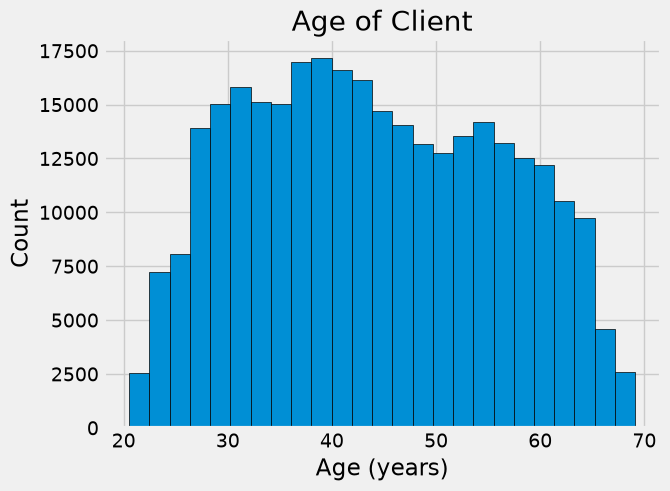

In [25]:
# Set the style of plots
plt.style.use('fivethirtyeight')

# Plot the distribution of ages in years
plt.hist(app_train['DAYS_BIRTH'] / 365, edgecolor = 'k', bins = 25)
plt.title('Age of Client'); plt.xlabel('Age (years)'); plt.ylabel('Count');

La distribution des âges ne révèle pas de valeurs aberrantes. Pour analyser l'effet de l'âge sur la cible, nous tracerons une estimation de densité par noyau (KDE) via `seaborn.kdeplot`, colorée selon la valeur de `TARGET`. La KDE est un histogramme lissé : un noyau (généralement gaussien) est calculé en chaque point, puis tous les noyaux sont moyennés en une courbe unique.

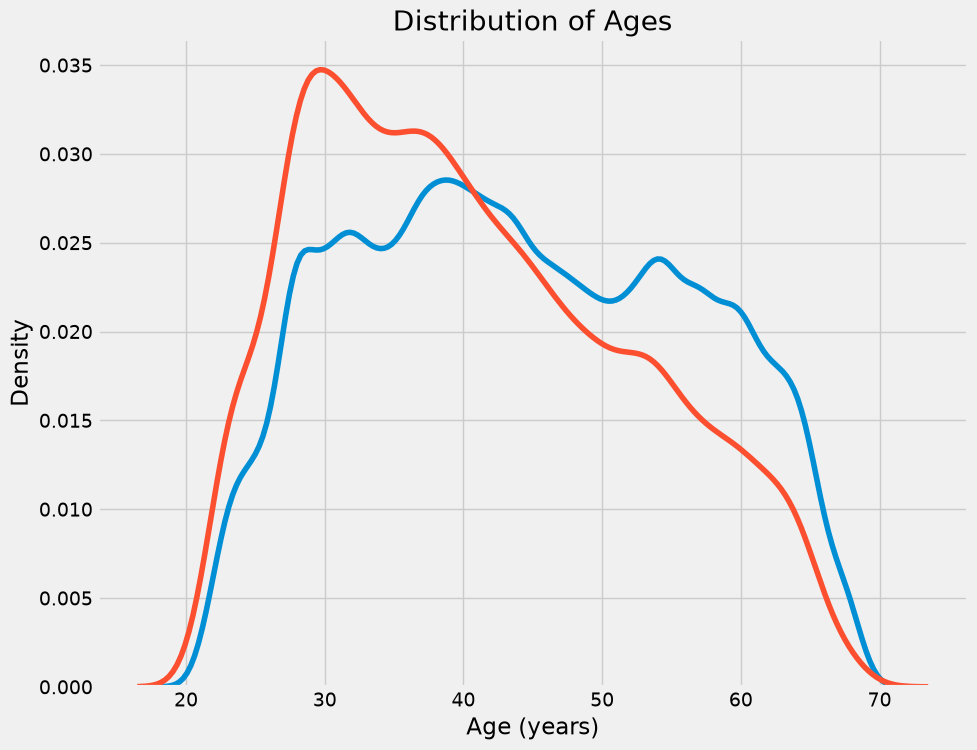

In [26]:
plt.figure(figsize = (10, 8))

# KDE plot of loans that were repaid on time
sns.kdeplot(app_train.loc[app_train['TARGET'] == 0, 'DAYS_BIRTH'] / 365, label = 'target == 0')

# KDE plot of loans which were not repaid on time
sns.kdeplot(app_train.loc[app_train['TARGET'] == 1, 'DAYS_BIRTH'] / 365, label = 'target == 1')

# Labeling of plot
plt.xlabel('Age (years)'); plt.ylabel('Density'); plt.title('Distribution of Ages');

Ce texte explique que, malgré un faible coefficient de corrélation (-0,07), l'âge (associé à la cible == 1) reste pertinent pour alimenter un modèle de machine learning. Pour mieux visualiser cette relation, on peut représenter le taux de défaut de remboursement des prêts en regroupant les âges par tranches de 5 ans.

In [27]:
# Age information into a separate dataframe
age_data = app_train[['TARGET', 'DAYS_BIRTH']]
age_data['YEARS_BIRTH'] = age_data['DAYS_BIRTH'] / 365

# Bin the age data
age_data['YEARS_BINNED'] = pd.cut(age_data['YEARS_BIRTH'], bins = np.linspace(20, 70, num = 11))
age_data.head(10)

,TARGET,DAYS_BIRTH,YEARS_BIRTH,YEARS_BINNED
0,1,9461,25.920548,"(25.0, 30.0]"
1,0,16765,45.931507,"(45.0, 50.0]"
2,0,19046,52.180822,"(50.0, 55.0]"
3,0,19005,52.068493,"(50.0, 55.0]"
4,0,19932,54.608219,"(50.0, 55.0]"
5,0,16941,46.413699,"(45.0, 50.0]"
6,0,13778,37.747945,"(35.0, 40.0]"
7,0,18850,51.643836,"(50.0, 55.0]"
8,0,20099,55.065753,"(55.0, 60.0]"
9,0,14469,39.641096,"(35.0, 40.0]"


In [28]:
# Group by the bin and calculate averages
age_groups  = age_data.groupby('YEARS_BINNED').mean()
age_groups

,TARGET,DAYS_BIRTH,YEARS_BIRTH
YEARS_BINNED,,,
"(20.0, 25.0]",0.123036,8532.795625,23.377522
"(25.0, 30.0]",0.111436,10155.219250,27.822518
"(30.0, 35.0]",0.102814,11854.848377,32.479037
"(35.0, 40.0]",0.089414,13707.908253,37.555913
"(40.0, 45.0]",0.078491,15497.661233,42.459346
"(45.0, 50.0]",0.074171,17323.900441,47.462741
"(50.0, 55.0]",0.066968,19196.494791,52.593136
"(55.0, 60.0]",0.055314,20984.262742,57.491131
"(60.0, 65.0]",0.052737,22780.547460,62.412459


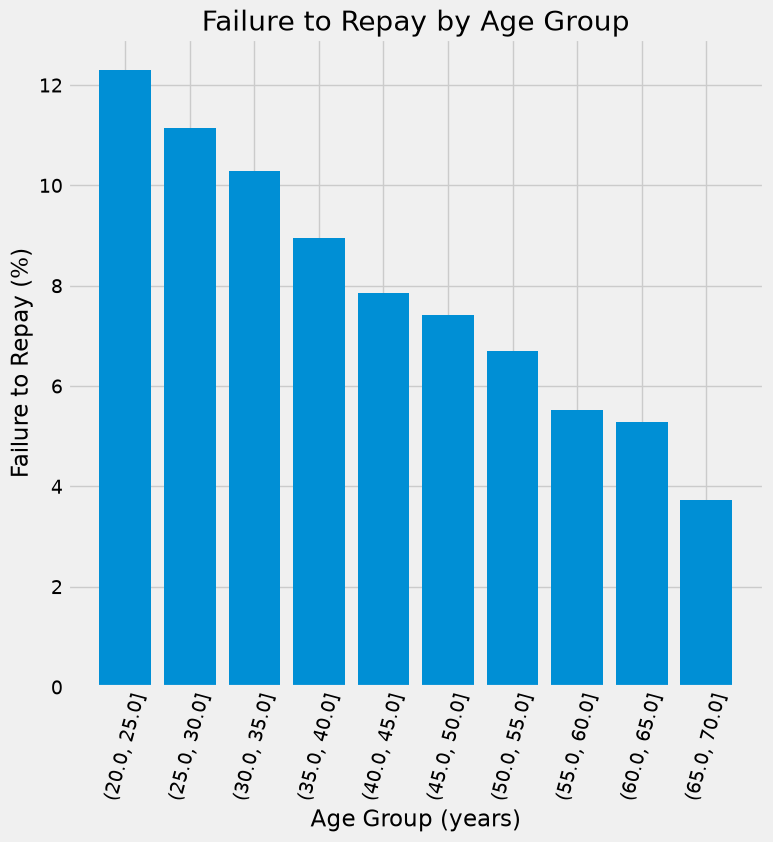

In [29]:
plt.figure(figsize = (8, 8))

# Graph the age bins and the average of the target as a bar plot
plt.bar(age_groups.index.astype(str), 100 * age_groups['TARGET'])

# Plot labeling
plt.xticks(rotation = 75); plt.xlabel('Age Group (years)'); plt.ylabel('Failure to Repay (%)')
plt.title('Failure to Repay by Age Group');

Le texte met en évidence une corrélation nette entre l'âge et le taux de défaut de remboursement (plus de 10 % chez les jeunes contre moins de 5 % chez les plus âgés). La banque peut exploiter ces données non pas pour exclure les jeunes emprunteurs, mais pour leur proposer un accompagnement et des mesures préventives adaptés.

Sources externes
Les 3 variables présentant les corrélations négatives les plus fortes avec la cible sont EXT_SOURCE_1, EXT_SOURCE_2 et EXT_SOURCE_3. D'après la documentation, ces caractéristiques représentent un « score normalisé provenant d'une source de données externe ». Je ne sais pas exactement ce que cela signifie.

In [30]:
# Extract the EXT_SOURCE variables and show correlations
ext_data = app_train[['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH']]
ext_data_corrs = ext_data.corr()
ext_data_corrs

,TARGET,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_BIRTH
TARGET,1.000000,-0.155317,-0.160472,-0.178919,-0.078239
EXT_SOURCE_1,-0.155317,1.000000,0.213982,0.186846,0.600610
EXT_SOURCE_2,-0.160472,0.213982,1.000000,0.109167,0.091996
EXT_SOURCE_3,-0.178919,0.186846,0.109167,1.000000,0.205478
DAYS_BIRTH,-0.078239,0.600610,0.091996,0.205478,1.000000


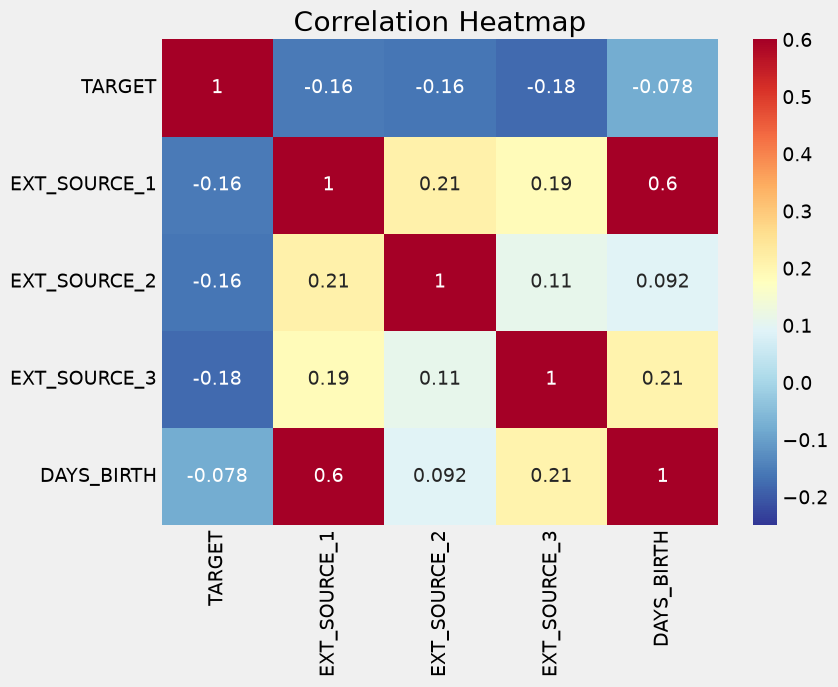

In [31]:
plt.figure(figsize = (8, 6))

# Heatmap of correlations
sns.heatmap(ext_data_corrs, cmap = plt.cm.RdYlBu_r, vmin = -0.25, annot = True, vmax = 0.6)
plt.title('Correlation Heatmap');

Les trois variables `EXT_SOURCE` présentent des corrélations négatives avec la variable cible, ce qui indique que plus la valeur de `EXT_SOURCE` est élevée, plus le client est susceptible de rembourser son prêt.

On constate également que `DAYS_BIRTH` est positivement corrélé à `EXT_SOURCE_1`, ce qui suggère que l'âge du client pourrait être un facteur influençant ce score.

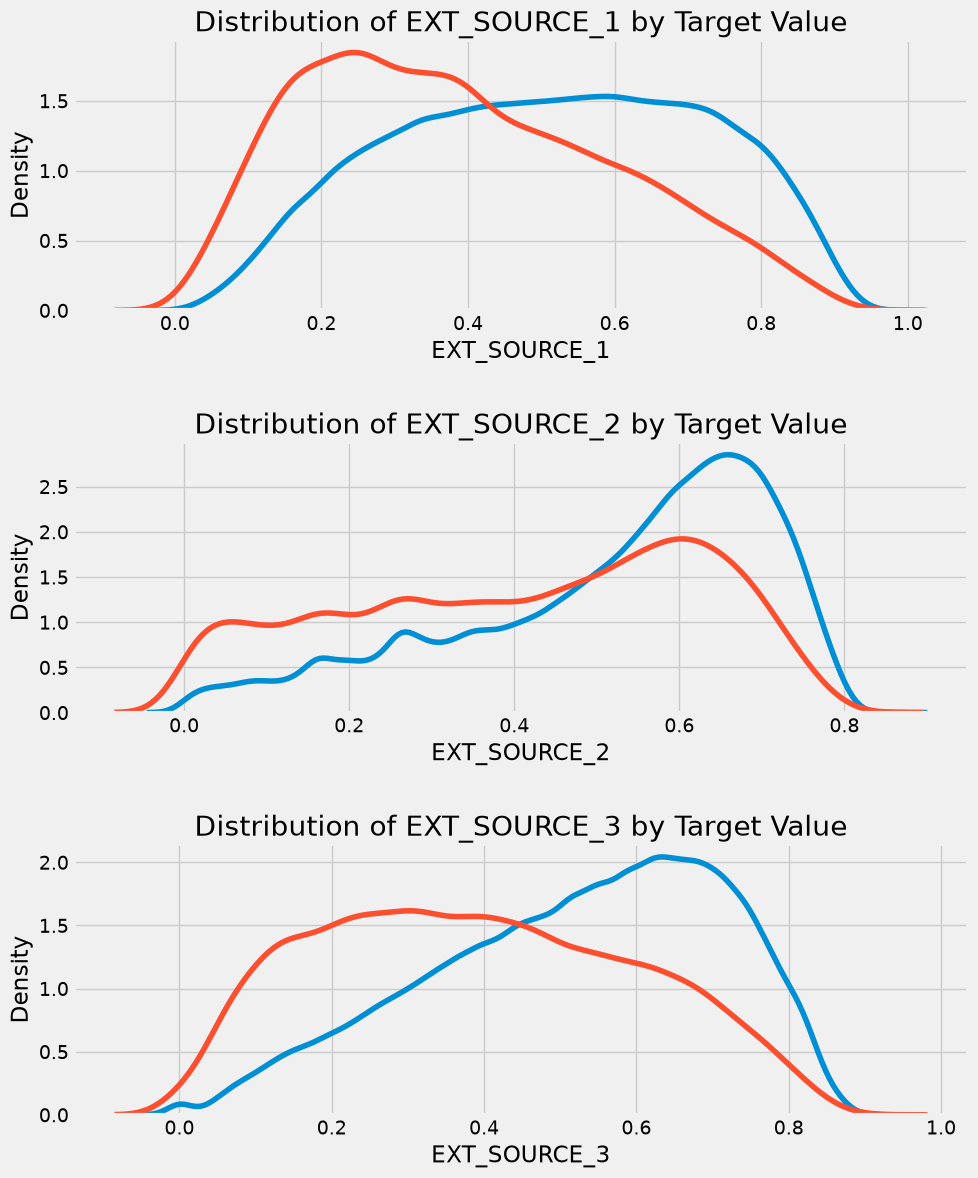

In [32]:
plt.figure(figsize = (10, 12))

# iterate through the sources
for i, source in enumerate(['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']):
    
    # create a new subplot for each source
    plt.subplot(3, 1, i + 1)
    # plot repaid loans
    sns.kdeplot(app_train.loc[app_train['TARGET'] == 0, source], label = 'target == 0')
    # plot loans that were not repaid
    sns.kdeplot(app_train.loc[app_train['TARGET'] == 1, source], label = 'target == 1')
    
    # Label the plots
    plt.title('Distribution of %s by Target Value' % source)
    plt.xlabel('%s' % source); plt.ylabel('Density');
    
plt.tight_layout(h_pad = 2.5)

La variable `EXT_SOURCE_3` présente la plus grande différence entre les valeurs cibles. On constate clairement que cette caractéristique est liée à la probabilité qu'un emprunteur rembourse un prêt.

Bien que cette corrélation soit faible (voire très faible pour toutes les variables), ces dernières restent utiles à un modèle d'apprentissage automatique pour prédire le remboursement d'un prêt dans les délais.

#### Diagramme de paires (Pairs Plot)

En guise de dernière exploration, nous pouvons créer un diagramme de paires à partir des variables EXT_SOURCE et DAYS_BIRTH. Ce type de diagramme est un excellent outil d'exploration car il permet de visualiser les relations entre plusieurs paires de variables, ainsi que la distribution de variables individuelles. Nous utilisons ici la bibliothèque de visualisation seaborn et la fonction PairGrid pour créer un diagramme de paires avec des nuages ​​de points dans le triangle supérieur, des histogrammes sur la diagonale et des graphiques de densité de noyau 2D et des coefficients de corrélation dans le triangle inférieur.

Si ce code vous paraît obscur, ne vous inquiétez pas ! La création de graphiques en Python peut s'avérer complexe, et pour tout graphique un peu plus élaboré, je préfère généralement trouver une implémentation existante et l'adapter (évitez de vous répéter !).

/home/artur/Documents/OpenClassrooms-DS/OpenClassrooms_P6/.venv/lib/python3.13/site-packages/seaborn/distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserWarning)
/home/artur/Documents/OpenClassrooms-DS/OpenClassrooms_P6/.venv/lib/python3.13/site-packages/seaborn/distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserWarning)
/home/artur/Documents/OpenClassrooms-DS/OpenClassrooms_P6/.venv/lib/python3.13/site-packages/seaborn/distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserWarning)
/home/artur/Documents/OpenClassrooms-DS/OpenClassrooms_P6/.venv/lib/python3.13/site-packages/seaborn/distributions.py:1128: UserWarning: cmap parameter ignored when using hue mapping.
  warnings.warn(msg, UserWarning)
/home/artur/Documents/OpenClassrooms-DS/OpenClassrooms_P6/.venv/lib/python3.13/site-packages/seaborn/distributions.py:1128: User

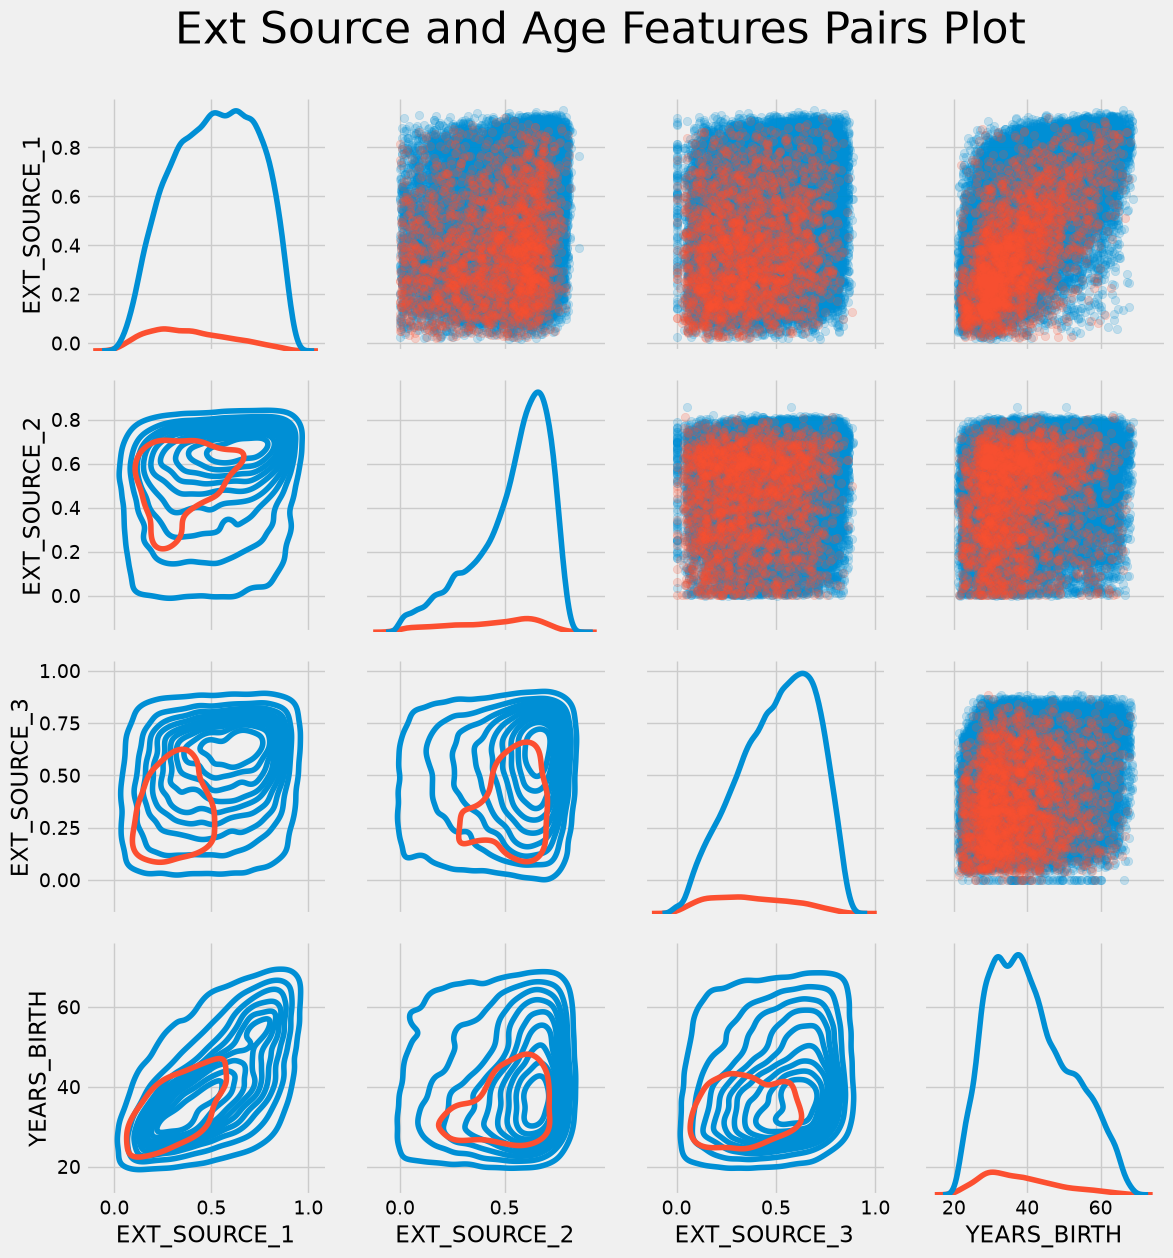

In [33]:
# Copy the data for plotting
plot_data = ext_data.drop(columns = ['DAYS_BIRTH']).copy()
  
# Add in the age of the client in years
plot_data['YEARS_BIRTH'] = age_data['YEARS_BIRTH']
  
# Drop na values and limit to first 100000 rows
plot_data = plot_data.dropna().loc[:100000, :]
  
# Function to calculate correlation coefficient between two columns
def corr_func(x, y, **kwargs):
    r = np.corrcoef(x, y)[0][1]
    ax = plt.gca()
    ax.annotate("r = {:.2f}".format(r), y=(.2, .8), xycoords=ax.transAxes, size = 20)

# Create the pairgrid object (remplacer size=3 par height=3)
grid = sns.PairGrid(data = plot_data, height = 3, diag_sharey=False,
                    hue = 'TARGET', 
                    vars = [x for x in list(plot_data.columns) if x != 'TARGET'])            
  
# Upper is a scatter plot
grid.map_upper(plt.scatter, alpha = 0.2)
  
# Diagonal is a histogram
grid.map_diag(sns.kdeplot)
  
# Bottom is density plot
grid.map_lower(sns.kdeplot, cmap = plt.cm.OrRd_r)
  
plt.suptitle('Ext Source and Age Features Pairs Plot', size = 32, y = 1.05)
plt.show()

Sur ce graphique, le rouge indique les prêts non remboursés et le bleu les prêts remboursés.

On observe différentes corrélations au sein des données.

Il semble exister une corrélation linéaire positive modérée entre `EXT_SOURCE_1` et `DAYS_BIRTH` (ou `YEARS_BIRTH`), ce qui suggère que cette variable pourrait tenir compte de l'âge du client.